In [11]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

In [5]:
data = np.load('cifar-10-python.npz')
x_train, x_test, y_train, y_test = data['x_train'], data['x_test'], data['y_train'], data['y_test']

In [6]:
#Normalize using min-max range
m,n = np.max(x_train), np.min(x_train)
x_train, x_test = (x_train-n)/(m-n) , (x_test-n)/(m-n)

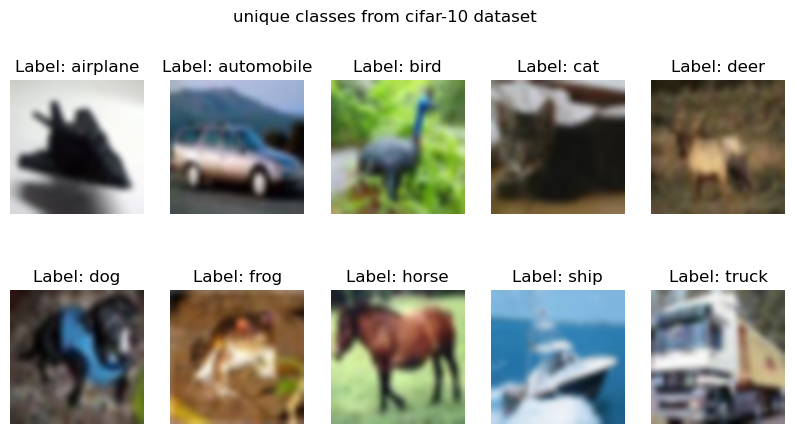

In [9]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog','frog', 'horse', 'ship', 'truck']
unique_labels, idx = np.unique(y_train, return_index= True)
fig, ax = plt.subplots(2,5, figsize=(10, 5))
for i , label in enumerate(unique_labels):
    ax.flat[i].imshow(x_train[idx[i]], interpolation='bicubic')
    ax.flat[i].set_title(f"Label: {class_names[label]}")
    ax.flat[i].axis("off")
plt.suptitle("unique classes from cifar-10 dataset")
plt.show()

In [12]:
data_augmentation = models.Sequential([
    layers.Resizing(64,64, input_shape = (32,32,3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1)
], name = "data_augmentation")

In [18]:
print("\n--- Traing Simple CNN Model ---")

simple_model = models.Sequential([
    data_augmentation,
    layers.Conv2D(32, (3,3), activation = 'relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation= 'relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(64, activation = 'relu'),
    layers.Dense(10, activation = 'softmax')
])

simple_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

#EalyStopping
early_stop_simple = keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights = True)

#training
simple_history = simple_model.fit(x_train, y_train, epochs=10, validation_split=0.2, callbacks=[early_stop_simple])


--- Traing Simple CNN Model ---
Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 42s 33ms/step - accuracy: 0.4103 - loss: 1.6206 - val_accuracy: 0.4943 - val_loss: 1.4112
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 40s 32ms/step - accuracy: 0.5165 - loss: 1.3542 - val_accuracy: 0.5688 - val_loss: 1.2145
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - accuracy: 0.5551 - loss: 1.2569 - val_accuracy: 0.5926 - val_loss: 1.1661
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 40s 32ms/step - accuracy: 0.5753 - loss: 1.1963 - val_accuracy: 0.6094 - val_loss: 1.1144
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - accuracy: 0.5909 - loss: 1.1576 - val_accuracy: 0.6245 - val_loss: 1.0786
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 43s 34ms/step - accuracy: 0.6054 - loss: 1.1181 - val_accuracy: 0.6159 - val_loss: 1.0825
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 41s 33ms/step - accuracy: 0.6156 - loss: 1.0873 - val_accuracy: 0.6429 - val_loss: 1.0372
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4

In [20]:
print("\n --- Training Improved CNN Model ---")

improved_model = models.Sequential([
    data_augmentation, 
    layers.Conv2D(32, (3,3), activation = 'relu', padding = 'same'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation = 'relu', padding = 'same'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation = 'relu', padding = 'same'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')
])

improved_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

early_stop_improved = keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 3, restore_best_weights=True)

#Training
improved_history = improved_model.fit(x_train, y_train, epochs=10, validation_split=0.2, callbacks= [early_stop_improved])


 --- Training Improved CNN Model ---
Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 59s 46ms/step - accuracy: 0.4318 - loss: 1.5700 - val_accuracy: 0.5370 - val_loss: 1.3288
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 60s 48ms/step - accuracy: 0.5547 - loss: 1.2496 - val_accuracy: 0.6150 - val_loss: 1.0862
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 61s 49ms/step - accuracy: 0.6050 - loss: 1.1207 - val_accuracy: 0.6561 - val_loss: 0.9784
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 61s 49ms/step - accuracy: 0.6272 - loss: 1.0568 - val_accuracy: 0.6741 - val_loss: 0.9232
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 61s 49ms/step - accuracy: 0.6485 - loss: 0.9944 - val_accuracy: 0.6843 - val_loss: 0.9069
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 61s 49ms/step - accuracy: 0.6626 - loss: 0.9491 - val_accuracy: 0.6997 - val_loss: 0.8589
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 60s 48ms/step - accuracy: 0.6785 - loss: 0.9173 - val_accuracy: 0.6908 - val_loss: 0.8787
Epoch 8/10
1250/1250 ━━━━━━━━━━━━━━━━━

In [21]:
simple_loss, simple_acc = simple_model.evaluate(x_test, y_test, verbose =1)
improved_loss, improved_acc = improved_model.evaluate(x_test, y_test, verbose =1)

print("\n--- Final performance comparision ---")
print(f"Simple CNN test accuracy: {simple_acc*100:.2f}%")
print(f"Improved CNN test accuracy: {improved_acc*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6533 - loss: 0.9892
313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.7095 - loss: 0.8170

--- Final performance comparision ---
Simple CNN test accuracy: 65.33%
Improved CNN test accuracy: 70.95%



Enter image index (0-9999):  5


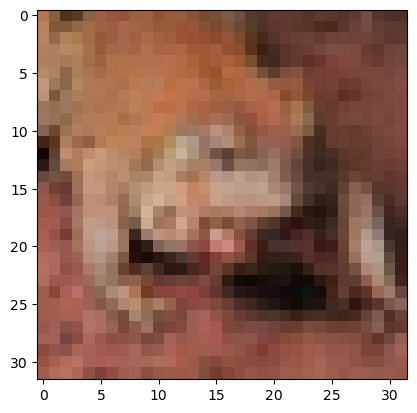

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
predicted class:  frog
Actual class:  frog


In [24]:
#Take random input image for the prediction
image_idx = int(input("\nEnter image index (0-9999): "))
plt.imshow(x_test[image_idx])
plt.show()

#predict using improved CNN
prediction = improved_model.predict(x_test[image_idx].reshape(1,32,32,3))

#Get predicted and actual class names
predicted_label = class_names[np.argmax(prediction[0])]
actual_label = class_name[int(y_test[image_idx])]

print("predicted class: ", predicted_label)
print("Actual class: ", actual_label)